# Analyse approfondie du segment **Decel** (décélérations)

Segment choisi : clients à **FM moyen ou élevé** (bonne fréquence / bon montant sur l'année) mais **récence faible** (dernier achat il y a plus de 150 jours). Ce sont les *RFM 2 et 3* de la slide 26 du cours, les « sleeping clients » : de la valeur, mais en train de s'endormir.

Ce notebook ré-exécute `Notebook_project1_completed.ipynb` pour récupérer `MASTER_RFM` et `RECEIPTS_INFO_RFM`, puis enregistre les graphiques dans `figures/` pour les slides.

In [1]:
%%capture
%run Notebook_project1_completed.ipynb

In [2]:
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import cross_val_score

os.makedirs('figures', exist_ok = True)

# Couleurs : Decel mis en avant, Top/Good en comparaison, le reste en retrait
DECEL = '#eb6834'
COMP = '#2a78d6'
OTHER = '#bdbbb4'
INK = '#0b0b0b'
INK2 = '#52514e'
LINE_COLORS = {'Corseterie': '#4a3aa7', 'Homewear': '#e87ba4', 'Bain': '#1baf7a'}

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': '#d6d4cd', 'axes.labelcolor': INK2,
    'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#ecebe6', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False,
})

SEG_ORDER = ['5 Top', '4 Good', '3 Decel', '2 Small', '1 Weak', 'New']
LABEL = {'5 Top': 'Top', '4 Good': 'Good', '3 Decel': 'Decel', '2 Small': 'Small', '1 Weak': 'Weak', 'New': 'New'}

def seg_color(s):
    return DECEL if s == '3 Decel' else (COMP if s in ('5 Top', '4 Good') else OTHER)

def save(fig, name):
    fig.savefig(f'figures/{name}.png', dpi = 200, bbox_inches = 'tight')

In [3]:
SEG = MASTER_RFM[['ID_INDIVIDU', 'RFM_SEG']]
R = RECEIPTS_INFO_RFM.merge(SEG, on = 'ID_INDIVIDU')
R['MONTH'] = R['DATE_ACHAT'].dt.month

D = MASTER_RFM.merge(
    CUSTOMERS_INFO[['ID_INDIVIDU', 'ETAT', 'TAILLE', 'TAILLE_BONNET']],
    on = 'ID_INDIVIDU',
    how = 'left'
)
is_decel = D['RFM_SEG'] == '3 Decel'
print(is_decel.sum(), 'clients Decel sur', len(D), 'clients actifs')

806 clients Decel sur 12340 clients actifs


## 1. Pourquoi Decel ? Le poids du segment

In [4]:
W = (
    MASTER_RFM
    .groupby('RFM_SEG')
    .agg(clients = ('ID_INDIVIDU', 'size'), CA = ('CUMUL_VALUE', 'sum'))
    .reindex(SEG_ORDER)
)
W['% clients'] = 100 * W['clients'] / W['clients'].sum()
W['% CA'] = 100 * W['CA'] / W['CA'].sum()
W['CA moyen / client'] = W['CA'] / W['clients']
W.round(1)

,clients,CA,% clients,% CA,CA moyen / client
RFM_SEG,,,,,
5 Top,1964,927949.0,15.9,28.3,472.5
4 Good,1584,593206.0,12.8,18.1,374.5
3 Decel,806,228125.0,6.5,7.0,283.0
2 Small,1510,161725.0,12.2,4.9,107.1
1 Weak,1782,177974.0,14.4,5.4,99.9
New,4694,1185916.0,38.0,36.2,252.6


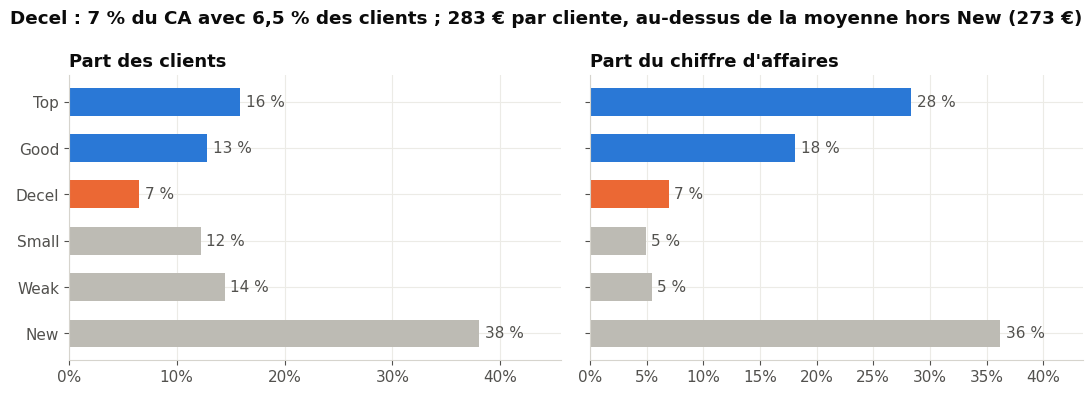

In [5]:
fig, axes = plt.subplots(1, 2, figsize = (11, 4), sharey = True)
labels = [LABEL[s] for s in SEG_ORDER]
colors = [seg_color(s) for s in SEG_ORDER]
for ax, col in zip(axes, ['% clients', '% CA']):
    bars = ax.barh(labels, W[col], color = colors, height = 0.6)
    ax.bar_label(bars, fmt = '%.0f %%', padding = 4, color = INK2)
    ax.set_title('Part des clients' if col == '% clients' else "Part du chiffre d'affaires")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals = 0))
    ax.set_xlim(0, W[col].max() * 1.2)
axes[0].invert_yaxis()
fig.suptitle("Decel : 7 % du CA avec 6,5 % des clients ; 283 € par cliente, au-dessus de la moyenne hors New (273 €)", x = 0.01, ha = 'left', fontweight = 'bold')
fig.tight_layout()
save(fig, '01_poids_segments')

## 2. Profil : le panier le plus élevé des clientes fidèles, mais moins de visites

Comparaison des indicateurs moyens, indexés sur la base active (hors New) = 100.

In [6]:
KPIS = {
    'CA annuel (€)': 'CUMUL_VALUE',
    'Nb de visites': 'NB_VISITS',
    'Panier moyen (€)': 'AVG_VISIT_VALUE',
    'Produits / visite': 'AVG_NB_PRODUCTS_VISIT',
    'Familles achetées': 'NB_FAMILIES',
    'Boutiques fréquentées': 'NB_STORES',
    'Cadeaux reçus': 'NB_GIFTS',
    'Récence (jours)': 'RECENCY',
    'Âge': 'AGE',
    'Ancienneté carte (ans)': 'SENIORITY',
}
old = MASTER_RFM[MASTER_RFM['RFM_SEG'] != 'New']
KPI = MASTER_RFM.groupby('RFM_SEG')[list(KPIS.values())].mean().reindex(SEG_ORDER)
KPI.loc['Base active (hors New)'] = old[list(KPIS.values())].mean()
KPI.columns = list(KPIS.keys())
KPI.round(1)

,CA annuel (€),Nb de visites,Panier moyen (€),Produits / visite,Familles achetées,Boutiques fréquentées,Cadeaux reçus,Récence (jours),Âge,Ancienneté carte (ans)
RFM_SEG,,,,,,,,,,
5 Top,472.5,5.2,94.7,3.5,6.3,1.7,3.7,32.9,46.0,3.8
4 Good,374.5,3.6,110.9,3.9,5.3,1.5,2.7,96.9,45.8,3.7
3 Decel,283.0,2.7,117.4,4.1,4.4,1.4,1.8,220.0,46.0,3.5
2 Small,107.1,1.2,97.3,3.2,2.3,1.1,0.3,76.4,46.4,3.7
1 Weak,99.9,1.1,94.2,3.3,2.3,1.0,0.4,254.7,45.1,3.5
New,252.6,1.9,151.7,5.4,3.9,1.2,1.5,131.2,44.6,0.5
Base active (hors New),273.2,2.9,100.9,3.5,4.2,1.3,1.8,126.2,45.8,3.7


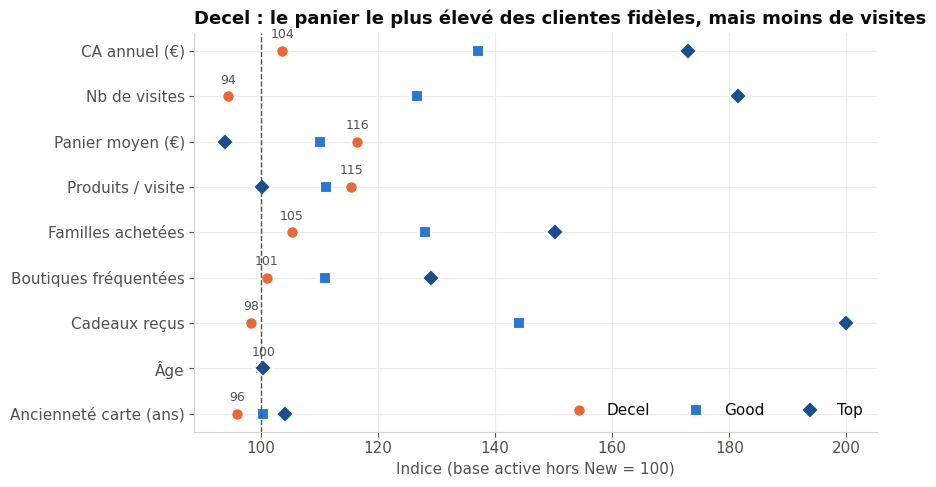

In [7]:
INDEX = (100 * KPI / KPI.loc['Base active (hors New)']).drop(columns = ['Récence (jours)'])
show = ['3 Decel', '4 Good', '5 Top']
fig, ax = plt.subplots(figsize = (9, 5))
y = range(len(INDEX.columns))
for s, mk in zip(show, ['o', 's', 'D']):
    ax.plot(INDEX.loc[s], y, mk, ms = 9, color = seg_color(s) if s == '3 Decel' else (COMP if s == '4 Good' else '#1a4f8f'),
            label = LABEL[s], markeredgecolor = 'white', markeredgewidth = 1.5, linestyle = 'none')
for yi, v in zip(y, INDEX.loc['3 Decel']):
    ax.annotate(f'{v:.0f}', (v, yi), textcoords = 'offset points', xytext = (0, 9), ha = 'center', color = INK2, fontsize = 9)
ax.axvline(100, color = INK2, lw = 1, ls = '--')
ax.set_yticks(list(y), INDEX.columns)
ax.invert_yaxis()
ax.set_xlabel('Indice (base active hors New = 100)')
ax.set_title('Decel : le panier le plus élevé des clientes fidèles, mais moins de visites')
ax.legend(loc = 'lower right', ncols = 3)
fig.tight_layout()
save(fig, '02_profil_indices')

## 3. Attention à la tautologie : ce que la définition impose

Une cliente Decel a une récence > 150 jours au 31/08/2016, donc **son dernier achat est forcément antérieur au 3 avril 2016**. Le fait qu'aucune Decel n'achète d'avril à août 2016 est une **conséquence mécanique de la définition**, pas un comportement. Pour comprendre le segment, il faut regarder **ce qui s'est passé avant** (sections 4 et 5).

Ce que l'on peut lire sans tautologie : **quand** a eu lieu leur dernier achat.

In [8]:
MONTH_ORDER = [9, 10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8]
MONTH_LABEL = ['sept', 'oct', 'nov', 'déc', 'janv', 'févr', 'mars', 'avr', 'mai', 'juin', 'juil', 'août']

print('Dernier achat Decel le plus tardif :', MASTER_RFM.loc[MASTER_RFM['RFM_SEG'] == '3 Decel', 'LAST_PURCHASE'].max().date())
last_month = pd.crosstab(
    MASTER_RFM['RFM_SEG'], MASTER_RFM['LAST_PURCHASE'].dt.month, normalize = 'index'
).reindex(index = SEG_ORDER, columns = MONTH_ORDER).fillna(0) * 100
last_month.columns = MONTH_LABEL
last_month.round(0)

Dernier achat Decel le plus tardif : 2016-04-02


,sept,oct,nov,déc,janv,févr,mars,avr,mai,juin,juil,août
RFM_SEG,,,,,,,,,,,,
5 Top,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,60.0,40.0
4 Good,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0,28.0,49.0,0.0,0.0
3 Decel,3.0,5.0,9.0,12.0,20.0,20.0,30.0,1.0,0.0,0.0,0.0,0.0
2 Small,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.0,18.0,22.0,26.0,14.0
1 Weak,13.0,13.0,10.0,15.0,22.0,13.0,13.0,0.0,0.0,0.0,0.0,0.0
New,4.0,4.0,4.0,6.0,3.0,4.0,8.0,10.0,12.0,15.0,14.0,15.0


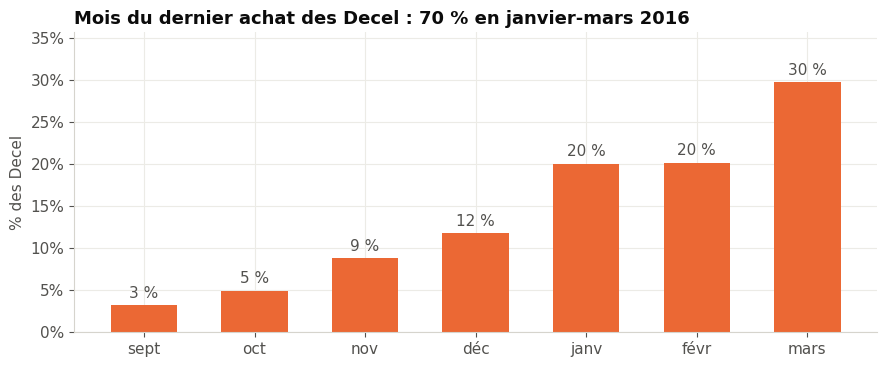

In [9]:
dec_last = last_month.loc['3 Decel', MONTH_LABEL[:7]]
fig, ax = plt.subplots(figsize = (9, 3.8))
bars = ax.bar(dec_last.index, dec_last.values, color = DECEL, width = 0.6)
ax.bar_label(bars, fmt = '%.0f %%', padding = 3, color = INK2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals = 0))
ax.set_ylim(0, dec_last.max() * 1.2)
ax.set_title(f"Mois du dernier achat des Decel : {dec_last[['janv', 'févr', 'mars']].sum():.0f} % en janvier-mars 2016")
ax.set_ylabel('% des Decel')
fig.tight_layout()
save(fig, '03_dernier_achat_decel')

**Lecture :** 7 Decel sur 10 ont acheté pour la dernière fois entre janvier et mars 2016 (contre 49 % des Weak : l'exigence d'un FM moyen ou élevé pousse mécaniquement le dernier achat vers une date tardive). Ce ne sont donc pas des clientes parties depuis longtemps : la plupart étaient encore actives quelques mois avant la fin de la période. La fenêtre d'action est courte, ce qui plaide pour une relance **dès avril**, avant que la cliente ne bascule en Decel.

## 4. Historique avant la période d'étude : deux profils de Decel

Les saisons sont découpées en automne-hiver (AH, sept.→mars) et printemps-été (PE, avr.→août). On ne garde que les saisons **antérieures à la période d'étude** (jusqu'au PE 2015) : les suivantes sont imposées par la définition des segments.

In [10]:
H = RECEIPTS_INFO_OK[RECEIPTS_INFO_OK['DATE_ACHAT'] <= max_date_RFM].merge(SEG, on = 'ID_INDIVIDU')

def season(d):
    y = d.year if d.month >= 9 else d.year - 1
    if d.month >= 9 or d.month <= 3:
        return f'AH {y}-{str(y + 1)[2:]}'
    return f'PE {d.year}'

H['SEASON'] = H['DATE_ACHAT'].map(season)
SEASON_ORDER = ['AH 2012-13', 'PE 2013', 'AH 2013-14', 'PE 2014', 'AH 2014-15', 'PE 2015']
ACTIVE = (
    H.groupby(['RFM_SEG', 'SEASON'])['ID_INDIVIDU'].nunique().unstack()
    .reindex(index = SEG_ORDER, columns = SEASON_ORDER)
    .div(MASTER_RFM['RFM_SEG'].value_counts(), axis = 0) * 100
)
ACTIVE.round(0)

SEASON,AH 2012-13,PE 2013,AH 2013-14,PE 2014,AH 2014-15,PE 2015
RFM_SEG,,,,,,
1 Weak,25.0,24.0,35.0,33.0,53.0,47.0
2 Small,25.0,26.0,35.0,36.0,50.0,48.0
3 Decel,26.0,24.0,38.0,35.0,65.0,59.0
4 Good,29.0,28.0,43.0,43.0,65.0,70.0
5 Top,34.0,35.0,47.0,52.0,71.0,77.0
New,NaN,NaN,NaN,NaN,NaN,0.0


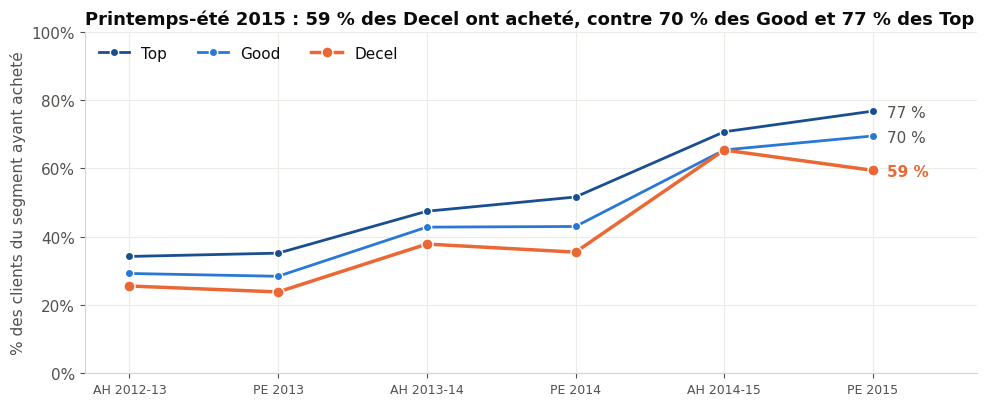

In [11]:
fig, ax = plt.subplots(figsize = (10, 4.2))
x = range(len(SEASON_ORDER))
for s in ['5 Top', '4 Good', '3 Decel']:
    ax.plot(x, ACTIVE.loc[s], lw = 2.5 if s == '3 Decel' else 2, marker = 'o', ms = 8 if s == '3 Decel' else 6,
            color = DECEL if s == '3 Decel' else (COMP if s == '4 Good' else '#1a4f8f'),
            markeredgecolor = 'white', label = LABEL[s])
for s in ['3 Decel', '4 Good', '5 Top']:
    ax.annotate(f"{ACTIVE.loc[s, 'PE 2015']:.0f} %", (5, ACTIVE.loc[s, 'PE 2015']), textcoords = 'offset points',
                xytext = (10, -4), ha = 'left', color = DECEL if s == '3 Decel' else INK2,
                fontweight = 'bold' if s == '3 Decel' else 'normal')
ax.set_xticks(list(x), SEASON_ORDER, fontsize = 9)
ax.set_xlim(-0.3, 5.7)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals = 0))
ax.set_ylim(0, 100)
ax.set_ylabel('% des clients du segment ayant acheté')
ax.set_title("Printemps-été 2015 : 59 % des Decel ont acheté, contre 70 % des Good et 77 % des Top")
ax.legend(loc = 'upper left', ncols = 3)
fig.tight_layout()
save(fig, '04_historique_saisons')

*La hausse générale d'une saison à l'autre reflète surtout l'ancienneté des cartes (les clientes récentes n'ont pas d'historique), pas une hausse d'activité.*

Avant même la période d'étude, les Decel étaient **moins présentes au printemps-été** que les Top et les Good (59 % contre 70-77 %), alors qu'elles l'étaient autant que les Good en automne-hiver 2014-15 (65 %).

In [12]:
prev_year = H[(H['DATE_ACHAT'] >= min_date_RFM - pd.DateOffset(years = 1)) & (H['DATE_ACHAT'] < min_date_RFM)]
N1 = prev_year.assign(PE = prev_year['DATE_ACHAT'].dt.month.between(4, 8))
N1_TAB = pd.DataFrame({
    'Clients actifs N-1': N1.groupby('RFM_SEG')['ID_INDIVIDU'].nunique(),
    'CA N-1 moyen (€)': N1.groupby(['RFM_SEG', 'ID_INDIVIDU'])['PRICE'].sum().groupby('RFM_SEG').mean(),
    'Part du CA N-1 au printemps-été (%)': N1[N1['PE']].groupby('RFM_SEG')['PRICE'].sum() / N1.groupby('RFM_SEG')['PRICE'].sum() * 100,
}).reindex(SEG_ORDER).drop(index = 'New')
N1_TAB.round(1)

,Clients actifs N-1,CA N-1 moyen (€),Part du CA N-1 au printemps-été (%)
RFM_SEG,,,
5 Top,1796,382.7,48.9
4 Good,1416,311.4,49.7
3 Decel,690,284.5,41.7
2 Small,1103,203.7,47.8
1 Weak,1329,199.2,45.4


⚠️ **Ne pas sur-interpréter la part printemps-été N-1 plus faible des Decel.** Elle vient mécaniquement des Decel qui n'ont rien acheté au printemps-été 2015 (profil B ci-dessous, part = 0 % par construction). Parmi les Decel qui achetaient l'été (profil A), la part printemps-été N-1 est aussi élevée que chez les Good (voir le calcul suivant). Le seul fait robuste : **41 % des Decel n'ont rien acheté au printemps-été 2015**, contre 30 % des Good et 23 % des Top.

In [13]:
summer15_ca = H[H['SEASON'] == 'PE 2015'].groupby('ID_INDIVIDU')['PRICE'].sum()
pe_before = set(H.loc[H['SEASON'].isin(['PE 2013', 'PE 2014']), 'ID_INDIVIDU'])
has_history = set(H.loc[H['DATE_ACHAT'] < min_date_RFM, 'ID_INDIVIDU'])

DEC = D[is_decel].copy()
DEC['PROFIL'] = np.where(
    DEC['ID_INDIVIDU'].isin(summer15_ca.index),
    'A. Actives au PE 2015, absentes au PE 2016',
    'B. Inactives au PE 2015',
)
DEC['CA_PE2015'] = DEC['ID_INDIVIDU'].map(summer15_ca).fillna(0)
DEC['PE_AVANT_2015'] = DEC['ID_INDIVIDU'].isin(pe_before)
DEC['SANS_HISTORIQUE'] = ~DEC['ID_INDIVIDU'].isin(has_history)

SUB = DEC.groupby('PROFIL').agg(
    clients = ('ID_INDIVIDU', 'size'),
    CA_annuel_moyen = ('CUMUL_VALUE', 'mean'),
    visites = ('NB_VISITS', 'mean'),
    recence = ('RECENCY', 'mean'),
    familles = ('NB_FAMILIES', 'mean'),
    anciennete = ('SENIORITY', 'mean'),
    age = ('AGE', 'mean'),
    achete_PE_2013_ou_2014 = ('PE_AVANT_2015', lambda s: s.mean() * 100),
    sans_historique_avant_sept15 = ('SANS_HISTORIQUE', lambda s: s.mean() * 100),
    CA_PE2015_moyen = ('CA_PE2015', 'mean'),
    CA_PE2015_total = ('CA_PE2015', 'sum'),
)
n1_A = N1[N1['ID_INDIVIDU'].isin(DEC.loc[DEC['PROFIL'].str.startswith('A'), 'ID_INDIVIDU'])]
print(f"Part du CA N-1 au printemps-été, profil A : {100 * n1_A.loc[n1_A['PE'], 'PRICE'].sum() / n1_A['PRICE'].sum():.1f} %")
SUB.round(1).T

Part du CA N-1 au printemps-été, profil A : 51.8 %


PROFIL,"A. Actives au PE 2015, absentes au PE 2016",B. Inactives au PE 2015
clients,479.0,327.0
CA_annuel_moyen,290.4,272.3
visites,2.8,2.5
recence,212.4,231.1
familles,4.5,4.2
anciennete,3.2,3.9
age,45.2,47.1
achete_PE_2013_ou_2014,42.2,46.5
sans_historique_avant_sept15,0.0,7.6
CA_PE2015_moyen,170.8,0.0


**Lecture :**
- **Profil A (479 clientes, 59 %) : actives au printemps-été 2015, absentes au printemps-été 2016.** Elles ont acheté en automne-hiver 2015-16 mais ne sont pas revenues au printemps. Leur CA printemps-été 2015 s'élevait à **≈ 82 k€** : c'est un **plafond** du CA printemps-été à reconquérir, pas une perte mesurée. Cible prioritaire : relance de printemps.
- **Profil B (327 clientes, 41 %) : inactives au printemps-été 2015.** Ce ne sont pas des « saisonnières pures » : près de la moitié (46 %) avaient acheté au printemps-été en 2013 ou 2014, autant que le profil A. Cible : leur (re)faire découvrir la collection printemps-été.

## 5. Produits : un moindre recours au bain, mesuré avant la période

⚠️ Le mix produit **pendant** la période est biaisé par la définition : le bain se vend d'avril à août, mois où les Decel ne peuvent pas avoir acheté. On le mesure donc sur l'**année précédente** (sept. 2014 → août 2015).

In [14]:
LINE_N1 = (
    pd.crosstab(N1['RFM_SEG'], N1['Ligne'], values = N1['PRICE'], aggfunc = 'sum', normalize = 'index')
    .reindex(index = [s for s in SEG_ORDER if s != 'New'])[['Corseterie', 'Homewear', 'Bain']] * 100
)
LINE_N1.round(1)

Ligne,Corseterie,Homewear,Bain
RFM_SEG,,,
5 Top,71.6,15.1,13.3
4 Good,70.9,14.9,14.2
3 Decel,73.4,15.7,10.9
2 Small,73.6,12.3,14.1
1 Weak,75.9,12.6,11.4


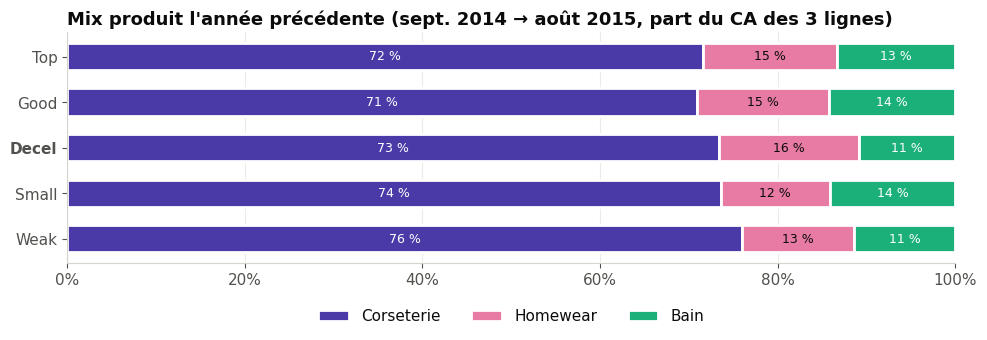

In [15]:
fig, ax = plt.subplots(figsize = (10, 3.6))
segs = list(LINE_N1.index)
left = np.zeros(len(segs))
labels_n1 = [LABEL[s] for s in segs]
for line in ['Corseterie', 'Homewear', 'Bain']:
    vals = LINE_N1[line].values
    bars = ax.barh(labels_n1, vals, left = left, color = LINE_COLORS[line], height = 0.6,
                   edgecolor = 'white', linewidth = 2, label = line)
    for b, v, l in zip(bars, vals, left):
        ax.text(l + v / 2, b.get_y() + b.get_height() / 2, f'{v:.0f} %', ha = 'center', va = 'center',
                color = 'white' if line != 'Homewear' else INK, fontsize = 9)
    left += vals
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals = 0))
ax.set_xlim(0, 100)
ax.get_yticklabels()[segs.index('3 Decel')].set_fontweight('bold')
ax.set_title("Mix produit l'année précédente (sept. 2014 → août 2015, part du CA des 3 lignes)")
ax.legend(loc = 'upper center', bbox_to_anchor = (0.5, -0.14), ncols = 3)
fig.tight_layout()
save(fig, '05_mix_produit_N-1')

In [16]:
# Adoption des gammes avant la période d'étude, parmi les clientes ayant un historique
before = H[H['DATE_ACHAT'] < min_date_RFM]
ever = before.assign(BAIN = before['Ligne'] == 'Bain', HOME = before['Ligne'] == 'Homewear').groupby('ID_INDIVIDU')[['BAIN', 'HOME']].any()
ADOPT = (
    SEG.merge(ever, left_on = 'ID_INDIVIDU', right_index = True, how = 'inner')
    .groupby('RFM_SEG')[['BAIN', 'HOME']].mean()
    .reindex([s for s in SEG_ORDER if s != 'New']) * 100
)
ADOPT.columns = ['Bain acheté avant sept. 2015 (%)', 'Homewear acheté avant sept. 2015 (%)']
ADOPT.round(0)

,Bain acheté avant sept. 2015 (%),Homewear acheté avant sept. 2015 (%)
RFM_SEG,,
5 Top,59.0,55.0
4 Good,53.0,46.0
3 Decel,41.0,42.0
2 Small,42.0,33.0
1 Weak,35.0,34.0


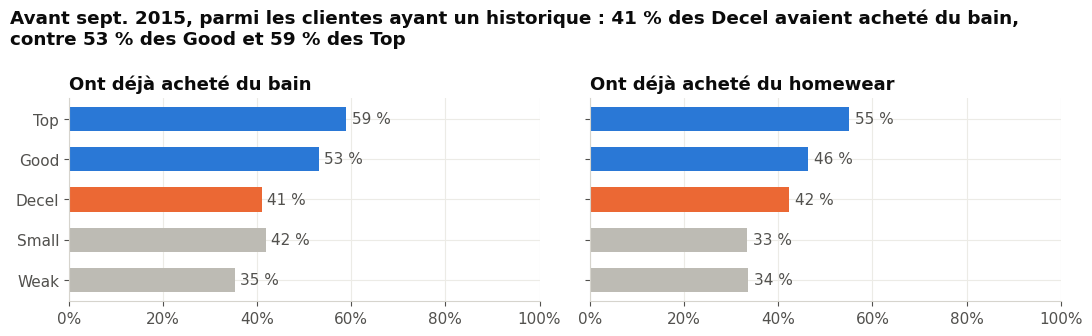

In [17]:
fig, axes = plt.subplots(1, 2, figsize = (11, 3.4), sharey = True)
segs = list(ADOPT.index)
for ax, col, title in zip(axes, ADOPT.columns, ['Ont déjà acheté du bain', 'Ont déjà acheté du homewear']):
    bars = ax.barh([LABEL[s] for s in segs], ADOPT[col], color = [seg_color(s) for s in segs], height = 0.6)
    ax.bar_label(bars, fmt = '%.0f %%', padding = 4, color = INK2)
    ax.set_title(title)
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals = 0))
axes[0].invert_yaxis()
fig.suptitle("Avant sept. 2015, parmi les clientes ayant un historique : 41 % des Decel avaient acheté du bain,\ncontre 53 % des Good et 59 % des Top", x = 0.01, ha = 'left', fontweight = 'bold')
fig.tight_layout()
save(fig, '06_adoption_gammes')

**Lecture :** avant la période d'étude, les Decel avaient nettement moins adopté la gamme bain (−12 points vs Good, −18 vs Top), alors que l'écart est plus faible sur le homewear (42 % contre 46 % pour les Good, 55 % pour les Top). Le mix N-1 va dans le même sens mais l'écart y est modeste (bain 11 % vs 13-14 %), en partie parce que le bain se vend l'été et que 41 % des Decel n'ont pas acheté au PE 2015.

*Limite :* l'adoption « déjà acheté » dépend aussi de l'ancienneté (3,5 ans pour les Decel contre 3,8 pour les Top) ; l'écart de 12 à 18 points paraît toutefois trop grand pour s'expliquer par ces quelques mois.

In [18]:
# Familles sur- et sous-représentées chez les Decel l'année précédente (indice vs base hors New)
n1_old = N1[N1['RFM_SEG'] != 'New']
n1_dec = n1_old[n1_old['RFM_SEG'] == '3 Decel']
FAM = pd.DataFrame({
    'Part CA Decel N-1 (%)': n1_dec.groupby('Famille')['PRICE'].sum() / n1_dec['PRICE'].sum() * 100,
    'Part CA base N-1 (%)': n1_old.groupby('Famille')['PRICE'].sum() / n1_old['PRICE'].sum() * 100,
}).dropna()
FAM['Indice'] = 100 * FAM['Part CA Decel N-1 (%)'] / FAM['Part CA base N-1 (%)']
FAM[FAM['Part CA base N-1 (%)'] > 1].sort_values('Indice', ascending = False).round(1)

,Part CA Decel N-1 (%),Part CA base N-1 (%),Indice
Famille,,,
Corseterie_PP,7.6,6.3,120.8
Homewear_Bas,4.8,4.3,111.3
Homewear_Haut,5.2,4.7,110.0
Homewear_Ensemble,4.7,4.4,105.6
Triangle/Brassiere,7.2,6.9,105.6
String/Tanga,11.2,10.6,105.1
Slip,10.1,9.7,104.3
Short,8.6,8.6,100.3
Corbeille,4.6,4.9,95.4


## 6. Qui sont-elles ? Pas de différence démographique

In [19]:
old_d = D[D['RFM_SEG'] != 'New']

def profile(g):
    return pd.Series({
        'Âge moyen': g['AGE'].mean(),
        'Ancienneté (ans)': g['SENIORITY'].mean(),
        'Part bonnet B (%)': (g['TAILLE_BONNET'].astype(str).str.upper() == 'B').mean() * 100,
        'Part visites boutique de rattachement (%)': g['SHARE_MANAGING_STORE'].mean() * 100,
    })

PROFILE = pd.DataFrame({s: profile(D[D['RFM_SEG'] == s]) for s in SEG_ORDER}).T
PROFILE.loc['Base active (hors New)'] = profile(old_d)
PROFILE.round(1)

,Âge moyen,Ancienneté (ans),Part bonnet B (%),Part visites boutique de rattachement (%)
5 Top,46.0,3.8,31.3,59.7
4 Good,45.8,3.7,31.1,62.1
3 Decel,46.0,3.5,29.3,64.3
2 Small,46.4,3.7,29.7,61.5
1 Weak,45.1,3.5,29.3,64.2
New,44.6,0.5,15.5,92.7
Base active (hors New),45.8,3.7,30.3,62.1


In [20]:
STORE_MIX = pd.crosstab(R['RFM_SEG'], R['CENTRE_VILLE'], normalize = 'index').reindex(SEG_ORDER) * 100
STORE_MIX['Paris (%)'] = pd.crosstab(R['RFM_SEG'], R['REGIONS'], normalize = 'index').reindex(SEG_ORDER)['Paris'] * 100
STORE_MIX.round(1)

CENTRE_VILLE,Centre Commercial,Centre ville,Paris (%)
RFM_SEG,,,
5 Top,25.3,74.7,35.5
4 Good,22.1,77.9,36.2
3 Decel,25.9,74.1,38.2
2 Small,30.0,70.0,34.2
1 Weak,30.5,69.5,34.0
New,23.0,77.0,43.4


*La variable `ETAT` (lieu de résidence) n'est pas utilisée : elle classe environ 40 % des clientes en Martinique alors que toutes les boutiques sont en métropole, ce qui la rend peu fiable.*

**Lecture :** âge, ancienneté, tailles, type de boutique et part des achats à Paris sont quasiment identiques d'un segment à l'autre et proches de la base. Ce qui distingue les Decel, c'est leur **comportement d'achat** (saisons, gammes), pas leur profil. Le ciblage doit donc reposer sur les **données de transaction**, pas sur des critères socio-démographiques.

## 7. Annexe : peut-on repérer une future Decel à l'avance ?

Arbre de décision (méthode de réaffectation du cours, slides 45-46 et 58) entraîné sur les clientes à FM moyen ou élevé (Top, Good, Decel). Les variables sont calculées **uniquement sur l'historique avant le 01/09/2015** (pas de fuite d'information), plus des variables client. Arbre non pondéré : les effectifs affichés sont les effectifs réels.

In [21]:
prev_visits = prev_year.groupby(['ID_INDIVIDU', 'CODE_BOUTIQUE', 'DATE_ACHAT', 'NUM_TICKET']).size().groupby('ID_INDIVIDU').size()
PRE = pd.DataFrame({
    'EVER_BAIN': before.assign(x = before['Ligne'] == 'Bain').groupby('ID_INDIVIDU')['x'].any(),
    'EVER_HOME': before.assign(x = before['Ligne'] == 'Homewear').groupby('ID_INDIVIDU')['x'].any(),
    'CA_N-1': prev_year.groupby('ID_INDIVIDU')['PRICE'].sum(),
    'VISITES_N-1': prev_visits,
    'PART_ETE_N-1': (
        prev_year['PRICE'].where(prev_year['DATE_ACHAT'].dt.month.between(4, 8), 0).groupby(prev_year['ID_INDIVIDU']).sum()
        / prev_year.groupby('ID_INDIVIDU')['PRICE'].sum().replace(0, np.nan)
    ),
})

T = D[D['RFM_SEG'].isin(['3 Decel', '4 Good', '5 Top'])].merge(PRE, left_on = 'ID_INDIVIDU', right_index = True, how = 'left')
FEATURES = ['EVER_BAIN', 'EVER_HOME', 'CA_N-1', 'VISITES_N-1', 'PART_ETE_N-1', 'SENIORITY', 'AGE']
X = T[FEATURES].astype(float)
X = X.fillna({'EVER_BAIN': 0, 'EVER_HOME': 0, 'CA_N-1': 0, 'VISITES_N-1': 0, 'PART_ETE_N-1': -1})
X = X.fillna(X.median())
# Classe 0 = Decel, classe 1 = Top/Good (pour garder l'orange des Decel dans le graphique)
y = (T['RFM_SEG'] != '3 Decel').astype(int)
print(f"Taux de Decel dans l'échantillon : {100 * (1 - y.mean()):.1f} % ({(y == 0).sum()} / {len(y)})")

tree = DecisionTreeClassifier(max_depth = 3, min_samples_leaf = 80, random_state = 0)
auc = cross_val_score(tree, X, y, cv = 5, scoring = 'roc_auc')
tree.fit(X, y)
print(f'AUC (validation croisée 5 plis) : {auc.mean():.3f} ± {auc.std():.3f}')
print(pd.Series(tree.feature_importances_, index = FEATURES).sort_values(ascending = False).round(3))

Taux de Decel dans l'échantillon : 18.5 % (806 / 4354)
AUC (validation croisée 5 plis) : 0.559 ± 0.084
VISITES_N-1     0.479
PART_ETE_N-1    0.331
EVER_BAIN       0.136
SENIORITY       0.054
EVER_HOME       0.000
CA_N-1          0.000
AGE             0.000
dtype: float64


3     28.7
4     24.3
6     21.0
7     14.3
10    22.7
11    11.1
13    10.1
14     4.6
Name: % Decel par feuille, dtype: float64


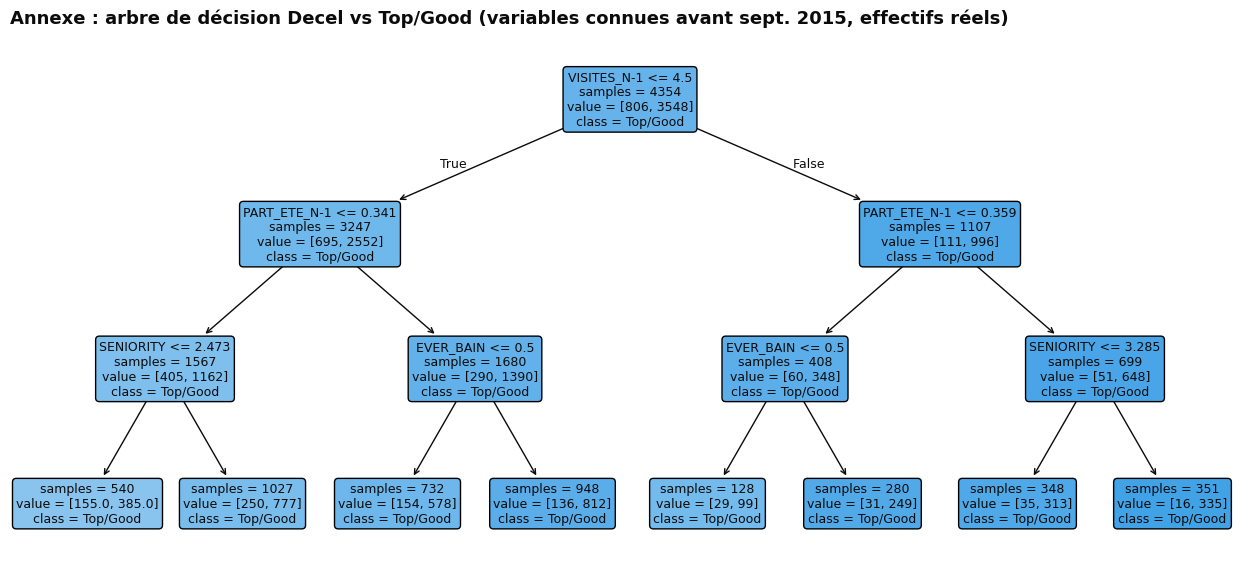

In [22]:
fig, ax = plt.subplots(figsize = (16, 7))
plot_tree(tree, feature_names = FEATURES, class_names = ['Decel', 'Top/Good'], filled = True, rounded = True,
          impurity = False, proportion = False, fontsize = 9, ax = ax)
ax.set_title("Annexe : arbre de décision Decel vs Top/Good (variables connues avant sept. 2015, effectifs réels)")
save(fig, '07_arbre_decision_annexe')

# Taux de Decel par feuille
leaf = tree.apply(X)
print((1 - pd.Series(y.values).groupby(leaf).mean()).mul(100).round(1).rename('% Decel par feuille'))

**Lecture :** les Top/Good restent majoritaires dans toutes les feuilles : l'arbre ne fait que faire varier le **taux** de Decel autour de la moyenne (18,5 %). L'AUC en validation croisée est proche du hasard : **l'historique d'achat ne suffit pas à prédire qui deviendra Decel**.

*Hypothèse (non démontrée ici)* : le passage en Decel dépendrait surtout d'événements de l'année (absence de relance au printemps, collection printemps-été non adoptée), non observés dans les données. D'où l'intérêt d'un **suivi en continu** (alerte si une cliente fidèle n'est pas revenue en avril) plutôt que d'un ciblage figé. Ce graphique est à garder en **annexe**.

## 8. Synthèse chiffrée pour les slides

In [23]:
is_A = DEC['PROFIL'].str.startswith('A')
summary = {
    'Clients Decel': len(DEC),
    'Part des clients actifs (%)': round(100 * len(DEC) / len(D), 1),
    'CA annuel Decel (€)': round(DEC['CUMUL_VALUE'].sum()),
    'Part du CA (%)': round(100 * DEC['CUMUL_VALUE'].sum() / D['CUMUL_VALUE'].sum(), 1),
    'CA moyen Decel (€)': round(DEC['CUMUL_VALUE'].mean(), 1),
    'CA moyen base hors New (€)': round(old_d['CUMUL_VALUE'].mean(), 1),
    'CA moyen Good (€)': round(D.loc[D['RFM_SEG'] == '4 Good', 'CUMUL_VALUE'].mean(), 1),
    'Panier moyen Decel (€)': round(DEC['AVG_VISIT_VALUE'].mean(), 1),
    'Dernier achat en janv.-mars 2016 (%)': round(last_month.loc['3 Decel', ['janv', 'févr', 'mars']].sum()),
    'Decel actives au PE 2015 (%)': round(ACTIVE.loc['3 Decel', 'PE 2015']),
    'Good actives au PE 2015 (%)': round(ACTIVE.loc['4 Good', 'PE 2015']),
    'Top actives au PE 2015 (%)': round(ACTIVE.loc['5 Top', 'PE 2015']),
    'Profil A (clients)': int(is_A.sum()),
    'Profil B (clients)': int((~is_A).sum()),
    'CA PE 2015 du profil A, plafond à reconquérir (€)': round(DEC.loc[is_A, 'CA_PE2015'].sum()),
    'Profil B ayant acheté au PE 2013 ou 2014 (%)': round(100 * DEC.loc[~is_A, 'PE_AVANT_2015'].mean()),
    'Decel ayant acheté du bain avant sept. 2015 (%)': round(ADOPT.loc['3 Decel'].iloc[0]),
    'Good ayant acheté du bain avant sept. 2015 (%)': round(ADOPT.loc['4 Good'].iloc[0]),
    'Top ayant acheté du bain avant sept. 2015 (%)': round(ADOPT.loc['5 Top'].iloc[0]),
    'Part du bain dans le CA N-1, Decel (%)': round(LINE_N1.loc['3 Decel', 'Bain'], 1),
    'Part du bain dans le CA N-1, Top (%)': round(LINE_N1.loc['5 Top', 'Bain'], 1),
    'Decel sans achat au PE 2015 (%)': round(100 - ACTIVE.loc['3 Decel', 'PE 2015']),
}
pd.Series(summary)

Clients Decel                                           806.0
Part des clients actifs (%)                               6.5
CA annuel Decel (€)                                  228125.0
Part du CA (%)                                            7.0
CA moyen Decel (€)                                      283.0
CA moyen base hors New (€)                              273.2
CA moyen Good (€)                                       374.5
Panier moyen Decel (€)                                  117.4
Dernier achat en janv.-mars 2016 (%)                     70.0
Decel actives au PE 2015 (%)                             59.0
Good actives au PE 2015 (%)                              70.0
Top actives au PE 2015 (%)                               77.0
Profil A (clients)                                      479.0
Profil B (clients)                                      327.0
CA PE 2015 du profil A, plafond à reconquérir (€)     81796.0
Profil B ayant acheté au PE 2013 ou 2014 (%)             46.0
Decel ay